In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import os
import json
import zipfile
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch version: 2.14.1+cpu
GPU available: False


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

Training device: cpu


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/WeatherPredictionPyTorch"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")
FIGURE_DIR = os.path.join(PROJECT_DIR, "figures")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

print("Project folders created successfully!")

Mounted at /content/drive
Project folders created successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload your WeatherAUS dataset.")

filename = next(iter(uploaded))

print("Uploaded file:", filename)

Saving weatherAUS.csv.zip to weatherAUS.csv.zip
Uploaded file: weatherAUS.csv.zip


In [ ]:
if filename.lower().endswith(".zip"):

    with zipfile.ZipFile(filename, "r") as zip_ref:

        csv_files = [
            f for f in zip_ref.namelist()
            if f.lower().endswith(".csv")
            and not f.startswith("__MACOSX/")
        ]

        if not csv_files:
            raise FileNotFoundError(
                "No CSV file found inside the ZIP archive."
            )

        csv_filename = csv_files[0]

        with zip_ref.open(csv_filename) as file:
            df = pd.read_csv(file)

elif filename.lower().endswith(".csv"):

    df = pd.read_csv(filename)

else:
    raise ValueError("Please upload a CSV or ZIP file.")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [ ]:
print("Dataset information:")
df.info()

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\nTarget distribution:")
display(df["RainTomorrow"].value_counts(dropna=False))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am

,Missing Values
Sunshine,69835
Evaporation,62790
Cloud3pm,59358
Cloud9am,55888
Pressure9am,15065
Pressure3pm,15028
WindDir9am,10566
WindGustDir,10326
WindGustSpeed,10263
Humidity3pm,4507



Target distribution:


,count
RainTomorrow,
No,110316
Yes,31877
NaN,3267


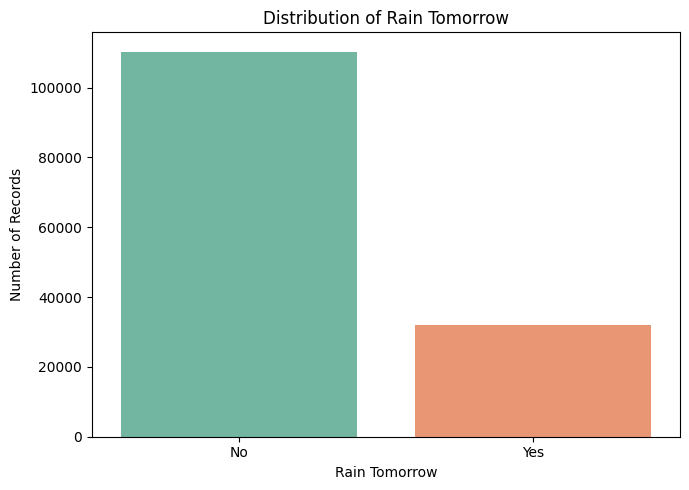

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="RainTomorrow",
    hue="RainTomorrow",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Rain Tomorrow")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "target_distribution.png"),
    dpi=300
)

plt.show()

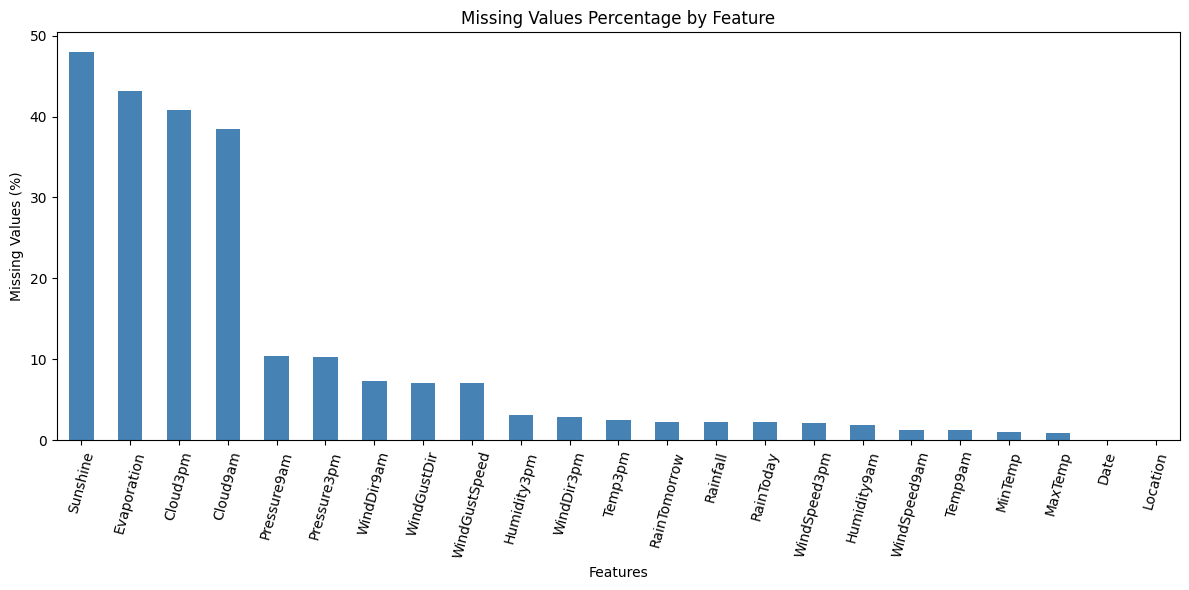

In [ ]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(12, 6))

missing_percentage.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "missing_values.png"),
    dpi=300
)

plt.show()

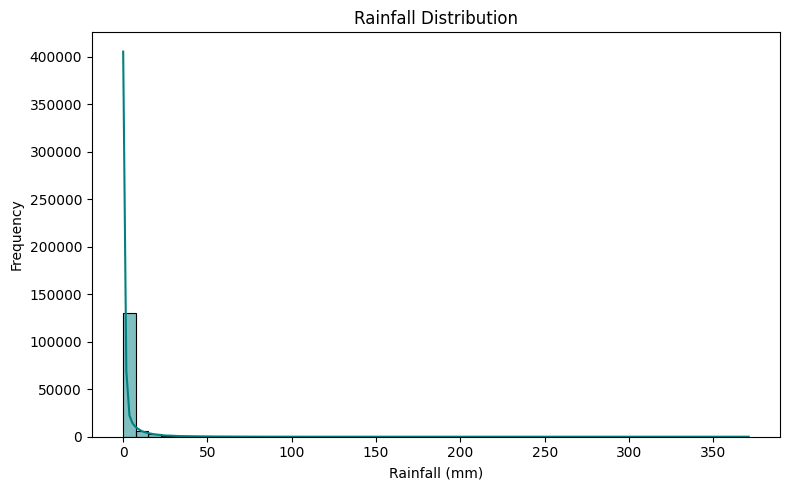

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Rainfall",
    bins=50,
    kde=True,
    color="teal"
)

plt.title("Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "rainfall_distribution.png"),
    dpi=300
)

plt.show()

In [ ]:
required_columns = [
    "Date",
    "Location",
    "RainTomorrow"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df = df.copy()

# Clean column names
df.columns = df.columns.str.strip()

# Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert dates
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# Clean target
df["RainTomorrow"] = (
    df["RainTomorrow"]
    .astype("string")
    .str.strip()
)

# Keep valid target values
df = df[
    df["RainTomorrow"].isin(["Yes", "No"])
].copy()

# Remove invalid dates
df = df.dropna(subset=["Date"])

# Remove duplicates
df = df.drop_duplicates()

# Extract month
df["Month"] = df["Date"].dt.month.astype(str)

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Cleaning completed!")
print("Clean dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["RainTomorrow"].value_counts())

Cleaning completed!
Clean dataset shape: (142193, 24)

Target distribution:
RainTomorrow
No     110316
Yes     31877
Name: count, dtype: Int64


In [ ]:
numeric_features = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Evaporation",
    "Sunshine",
    "WindGustSpeed",
    "WindSpeed9am",
    "WindSpeed3pm",
    "Humidity9am",
    "Humidity3pm",
    "Pressure9am",
    "Pressure3pm",
    "Cloud9am",
    "Cloud3pm",
    "Temp9am",
    "Temp3pm"
]

categorical_features = [
    "Location",
    "WindGustDir",
    "WindDir9am",
    "WindDir3pm",
    "RainToday",
    "Month"
]

feature_columns = numeric_features + categorical_features

target_column = "RainTomorrow"

# Check required features
missing_features = [
    col for col in feature_columns
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing model features: {missing_features}"
    )

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(feature_columns))

Numeric features: 16
Categorical features: 6
Total features: 22


In [ ]:
df = df.sort_values("Date").reset_index(drop=True)

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining date range:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting date range:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Training records: 99535
Validation records: 14219
Testing records: 28439

Training date range:
2007-11-01 00:00:00 to 2015-01-12 00:00:00

Testing date range:
2015-11-10 00:00:00 to 2017-06-25 00:00:00


In [ ]:
# Numeric preprocessing
numeric_medians = {}
numeric_means = {}
numeric_stds = {}

for col in numeric_features:

    values = pd.to_numeric(
        train_df[col],
        errors="coerce"
    )

    median = values.median()

    if pd.isna(median):
        median = 0.0

    filled = values.fillna(median)

    mean = filled.mean()
    std = filled.std()

    if pd.isna(std) or std == 0:
        std = 1.0

    numeric_medians[col] = float(median)
    numeric_means[col] = float(mean)
    numeric_stds[col] = float(std)


# Categorical preprocessing
categorical_modes = {}
categorical_categories = {}

for col in categorical_features:

    values = train_df[col].astype("string").str.strip()

    mode_values = values.dropna().mode()

    if len(mode_values) == 0:
        mode = "Unknown"
    else:
        mode = str(mode_values.iloc[0])

    filled = values.fillna(mode).astype(str)

    categorical_modes[col] = mode

    categorical_categories[col] = sorted(
        filled.unique().tolist()
    )

print("Preprocessing fitted successfully!")

Preprocessing fitted successfully!


In [ ]:
def transform_features(data):

    numeric_parts = []
    categorical_parts = []

    # Numeric features
    for col in numeric_features:

        values = pd.to_numeric(
            data[col],
            errors="coerce"
        )

        values = values.fillna(
            numeric_medians[col]
        )

        standardized = (
            values.to_numpy(dtype=np.float32)
            - numeric_means[col]
        ) / numeric_stds[col]

        numeric_parts.append(standardized.reshape(-1, 1))


    # Categorical features
    for col in categorical_features:

        values = (
            data[col]
            .astype("string")
            .str.strip()
            .fillna(categorical_modes[col])
            .astype(str)
        )

        categories = categorical_categories[col]

        encoded = np.column_stack([
            (values.to_numpy() == category).astype(np.float32)
            for category in categories
        ])

        categorical_parts.append(encoded)


    X = np.concatenate(
        numeric_parts + categorical_parts,
        axis=1
    ).astype(np.float32)

    return X


X_train = transform_features(train_df)
X_val = transform_features(val_df)
X_test = transform_features(test_df)

# No = 0, Yes = 1
y_train = (
    train_df[target_column] == "Yes"
).astype(np.float32).to_numpy()

y_val = (
    val_df[target_column] == "Yes"
).astype(np.float32).to_numpy()

y_test = (
    test_df[target_column] == "Yes"
).astype(np.float32).to_numpy()

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)
print("Testing input shape:", X_test.shape)
print("Input feature count:", X_train.shape[1])

Training input shape: (99535, 127)
Validation input shape: (14219, 127)
Testing input shape: (28439, 127)
Input feature count: 127


In [ ]:
BATCH_SIZE = 1024

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
class WeatherPredictionNN(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):

        return self.network(x)


input_dim = X_train.shape[1]

model = WeatherPredictionNN(input_dim).to(device)

print(model)
print("\nInput dimensions:", input_dim)

WeatherPredictionNN(
  (network): Sequential(
    (0): Linear(in_features=127, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.25, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.15, inplace=False)
    (9): Linear(in_features=64, out_features=1, bias=True)
  )
)

Input dimensions: 127


In [ ]:
positive_count = np.sum(y_train == 1)
negative_count = np.sum(y_train == 0)

if positive_count == 0 or negative_count == 0:
    raise ValueError(
        "Training data must contain both Yes and No classes."
    )

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Positive samples:", positive_count)
print("Negative samples:", negative_count)
print("Positive class weight:", pos_weight.item())

Positive samples: 22455
Negative samples: 77080
Positive class weight: 3.432643175125122


In [ ]:
EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}


for epoch in range(EPOCHS):

    # Training
    model.train()

    train_loss_total = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device).view(-1, 1)

        optimizer.zero_grad()

        outputs = model(batch_X)

        loss = criterion(outputs, batch_y)

        loss.backward()

        optimizer.step()

        train_loss_total += loss.item() * len(batch_X)

    train_loss = train_loss_total / len(train_dataset)


    # Validation
    model.eval()

    val_loss_total = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device).view(-1, 1)

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            val_loss_total += loss.item() * len(batch_X)

    val_loss = val_loss_total / len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)


    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


    # Save best weights in memory
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activated.")

        break


if best_state is None:
    raise RuntimeError("Training did not produce a valid model.")

model.load_state_dict(best_state)

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)

Epoch 01/30 | Train Loss: 0.7618 | Validation Loss: 0.6810
Epoch 02/30 | Train Loss: 0.6753 | Validation Loss: 0.6637
Epoch 03/30 | Train Loss: 0.6551 | Validation Loss: 0.6434
Epoch 04/30 | Train Loss: 0.6388 | Validation Loss: 0.6523
Epoch 05/30 | Train Loss: 0.6251 | Validation Loss: 0.6374
Epoch 06/30 | Train Loss: 0.6146 | Validation Loss: 0.6397
Epoch 07/30 | Train Loss: 0.6051 | Validation Loss: 0.6347
Epoch 08/30 | Train Loss: 0.5987 | Validation Loss: 0.6365
Epoch 09/30 | Train Loss: 0.5878 | Validation Loss: 0.6366
Epoch 10/30 | Train Loss: 0.5831 | Validation Loss: 0.6503
Epoch 11/30 | Train Loss: 0.5746 | Validation Loss: 0.6442
Epoch 12/30 | Train Loss: 0.5665 | Validation Loss: 0.6461

Early stopping activated.

Training completed!
Best validation loss: 0.6346802642907311


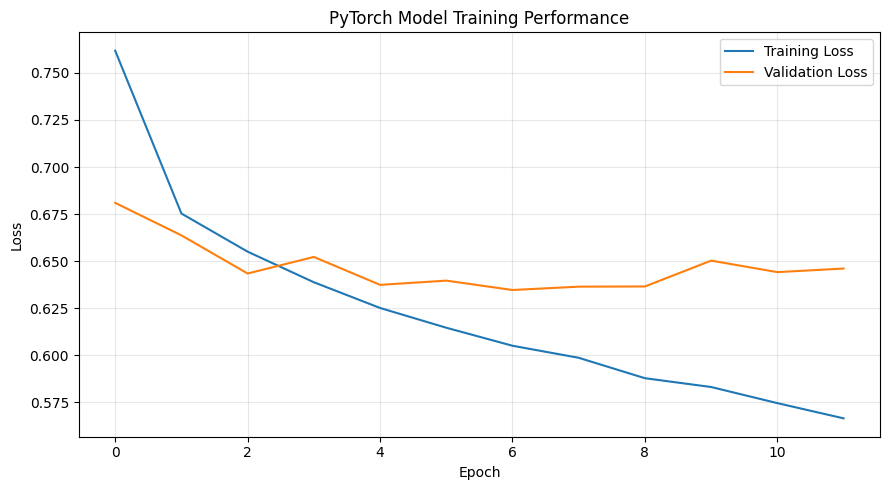

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("PyTorch Model Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "training_loss.png"),
    dpi=300
)

plt.show()

In [ ]:
def predict_probabilities(data_loader):

    model.eval()

    all_probabilities = []

    with torch.no_grad():

        for batch_X, _ in data_loader:

            batch_X = batch_X.to(device)

            logits = model(batch_X)

            probabilities = torch.sigmoid(logits)

            all_probabilities.extend(
                probabilities.cpu().numpy().ravel()
            )

    return np.array(all_probabilities)


val_probabilities = predict_probabilities(val_loader)

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    score = f1_score(
        y_val,
        val_predictions,
        zero_division=0
    )

    threshold_results.append(score)

best_threshold = float(
    thresholds[np.argmax(threshold_results)]
)

print("Selected probability threshold:", best_threshold)
print(
    "Validation F1-score:",
    max(threshold_results)
)

Selected probability threshold: 0.6599999999999997
Validation F1-score: 0.6586670990757256


In [ ]:
test_probabilities = predict_probabilities(test_loader)

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

accuracy = accuracy_score(
    y_test,
    test_predictions
)

precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

auc = roc_auc_score(
    y_test,
    test_probabilities
)

print("FINAL TEST RESULTS")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Rain", "Rain"],
        zero_division=0
    )
)

FINAL TEST RESULTS
-------------------------
Accuracy:  0.8446
Precision: 0.6405
Recall:    0.6930
F1-score:  0.6657
ROC-AUC:   0.8860

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.91      0.89      0.90     22090
        Rain       0.64      0.69      0.67      6349

    accuracy                           0.84     28439
   macro avg       0.78      0.79      0.78     28439
weighted avg       0.85      0.84      0.85     28439



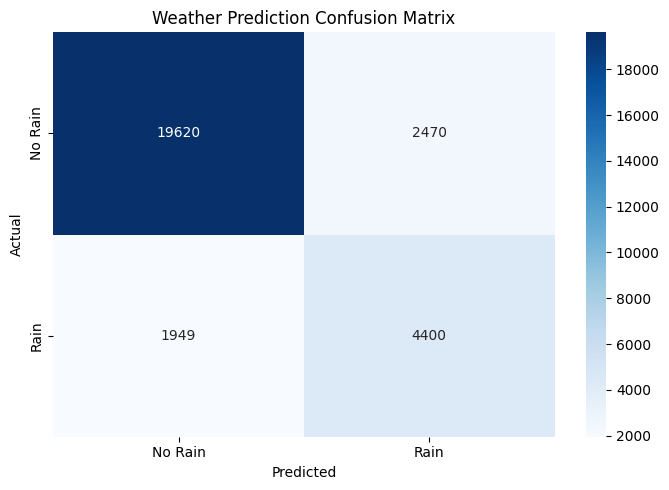

In [ ]:
cm = confusion_matrix(
    y_test,
    test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)

plt.title("Weather Prediction Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()

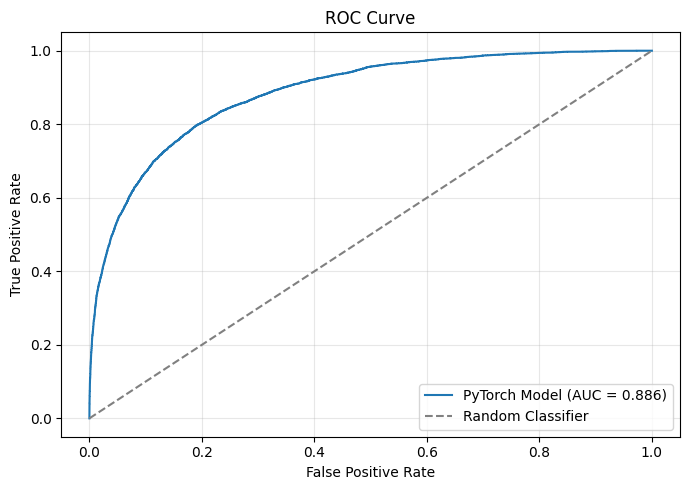

In [ ]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"PyTorch Model (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "roc_curve.png"),
    dpi=300
)

plt.show()

In [ ]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "weather_prediction_model.pt"
)

torch.save(
    {
        key: value.detach().cpu()
        for key, value in model.state_dict().items()
    },
    MODEL_PATH
)

print("PyTorch model saved successfully!")
print(MODEL_PATH)

PyTorch model saved successfully!
/content/drive/MyDrive/WeatherPredictionPyTorch/models/weather_prediction_model.pt


In [ ]:
metadata = {
    "project_name": "Weather Prediction System",
    "model_name": "PyTorch Neural Network",
    "target_column": "RainTomorrow",
    "target_classes": {
        "No": 0,
        "Yes": 1
    },
    "positive_class": "Yes",
    "input_dim": int(input_dim),
    "hidden_dims": [256, 128, 64],
    "dropout": [0.30, 0.25, 0.15],
    "threshold": best_threshold,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_columns": feature_columns,
    "numeric_medians": numeric_medians,
    "numeric_means": numeric_means,
    "numeric_stds": numeric_stds,
    "categorical_modes": categorical_modes,
    "categorical_categories": categorical_categories
}

METADATA_PATH = os.path.join(
    MODEL_DIR,
    "model_metadata.json"
)

with open(METADATA_PATH, "w") as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("Model metadata saved successfully!")

Model metadata saved successfully!


In [ ]:
results = {
    "Model": "PyTorch Neural Network",
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1_Score": float(f1),
    "ROC_AUC": float(auc),
    "Threshold": float(best_threshold),
    "Training_Records": int(len(train_df)),
    "Validation_Records": int(len(val_df)),
    "Testing_Records": int(len(test_df))
}

results_path = os.path.join(
    REPORT_DIR,
    "model_evaluation_results.json"
)

with open(results_path, "w") as f:

    json.dump(
        results,
        f,
        indent=4
    )

print(json.dumps(results, indent=4))

{
    "Model": "PyTorch Neural Network",
    "Accuracy": 0.8446147895495623,
    "Precision": 0.6404657933042213,
    "Recall": 0.6930225232320051,
    "F1_Score": 0.6657084499583932,
    "ROC_AUC": 0.8860136880433223,
    "Threshold": 0.6599999999999997,
    "Training_Records": 99535,
    "Validation_Records": 14219,
    "Testing_Records": 28439
}


In [ ]:
verification_model = WeatherPredictionNN(input_dim).to(device)

saved_weights = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

verification_model.load_state_dict(saved_weights)

verification_model.eval()
model.eval()

sample = torch.tensor(
    X_test[:10],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    original_predictions = torch.sigmoid(
        model(sample)
    )

    loaded_predictions = torch.sigmoid(
        verification_model(sample)
    )

difference = torch.max(
    torch.abs(
        original_predictions - loaded_predictions
    )
).item()

print("Maximum prediction difference:", difference)

assert difference < 1e-6

print("SUCCESS: Saved model verified!")

Maximum prediction difference: 0.0
SUCCESS: Saved model verified!


In [ ]:
import shutil

BUNDLE_PATH = os.path.join(
    PROJECT_DIR,
    "WeatherPrediction_PyTorch_Bundle.zip"
)

with zipfile.ZipFile(BUNDLE_PATH, "w") as zipf:

    zipf.write(
        MODEL_PATH,
        arcname="weather_prediction_model.pt"
    )

    zipf.write(
        METADATA_PATH,
        arcname="model_metadata.json"
    )

    zipf.write(
        results_path,
        arcname="model_evaluation_results.json"
    )

    for filename in os.listdir(FIGURE_DIR):

        filepath = os.path.join(
            FIGURE_DIR,
            filename
        )

        if os.path.isfile(filepath):

            zipf.write(
                filepath,
                arcname=f"figures/{filename}"
            )

print("Bundle created successfully!")
print(BUNDLE_PATH)

Bundle created successfully!
/content/drive/MyDrive/WeatherPredictionPyTorch/WeatherPrediction_PyTorch_Bundle.zip


In [ ]:
from google.colab import files

files.download(BUNDLE_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>